In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load the Data

In [163]:
# load both csvs into df
cust_df = pd.read_csv('Customer_Master_Data.csv')
trans_df = pd.read_csv('Customer_Transactions.csv')

In [164]:
# Check shape, structure and preview
print('\t\t\t\t\t Customer Master Dataset')
print(f'Shape: {cust_df.shape}')
print(f'Structure & Preview: ')
cust_df.info()

					 Customer Master Dataset
Shape: (1000, 9)
Structure & Preview: 
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     1000 non-null   str  
 1   Name           1000 non-null   str  
 2   Email          1000 non-null   str  
 3   Gender         1000 non-null   str  
 4   Age            1000 non-null   int64
 5   City           1000 non-null   str  
 6   MaritalStatus  1000 non-null   str  
 7   NumChildren    1000 non-null   int64
 8   JoinDate       1000 non-null   str  
dtypes: int64(2), str(7)
memory usage: 70.4 KB


In [165]:
# Check shape, structure and preview
print('\t\t\t\t\t Customer Trasactions Dataset')
print(f'Shape: {trans_df.shape}')
print(f'Structure & Preview: ')
trans_df.info()

					 Customer Trasactions Dataset
Shape: (23050, 3)
Structure & Preview: 
<class 'pandas.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         23050 non-null  str    
 1   TransactionDate    23050 non-null  str    
 2   TransactionAmount  23050 non-null  float64
dtypes: float64(1), str(2)
memory usage: 540.4 KB


# Step 2: Clean the Data

In [166]:
# Convert JoinDate and TransactionDate columns to datetime

# Joindate
cust_df['JoinDate'] = pd.to_datetime(cust_df['JoinDate'])
print(f'JoinDate dtype: {cust_df['JoinDate'].dtype}')

# TransactionDate
trans_df['TransactionDate'] = pd.to_datetime(trans_df['TransactionDate'])
print(f'TransactionDate dtype: {trans_df['TransactionDate'].dtype}')


JoinDate dtype: datetime64[us]


C:\Users\dell\AppData\Local\Temp\ipykernel_7684\24018751.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  trans_df['TransactionDate'] = pd.to_datetime(trans_df['TransactionDate'])


TransactionDate dtype: datetime64[us]


In [167]:
# Ensure no nulls or bad types

# cust_df no null
print(cust_df.isna().sum())

print('-'*30)

# cust_df no null
print(trans_df.isna().sum())


CustomerID       0
Name             0
Email            0
Gender           0
Age              0
City             0
MaritalStatus    0
NumChildren      0
JoinDate         0
dtype: int64
------------------------------
CustomerID           0
TransactionDate      0
TransactionAmount    0
dtype: int64


In [168]:
# Validate uniqueness of CustomerID in master dataset

print(f'Total customers: {cust_df.shape[0]}')
print(f'Total unique customers: {cust_df.CustomerID.nunique()}')
print('All customer ID are unique')

Total customers: 1000
Total unique customers: 1000
All customer ID are unique


In [169]:
# Ensure all transaction CustomerIDs exist in master data
print('All 1000 customer id of master dataset exist in transaction dataset')
trans_df['CustomerID'].unique().isin(cust_df['CustomerID']).sum()


All 1000 customer id of master dataset exist in transaction dataset


np.int64(1000)

# Step 3: Merge


In [170]:
# merge bth the datasets with left join on transactions dataset
merged_df = pd.merge(trans_df, cust_df, how='left', on='CustomerID')
print(f'Shape: {merged_df.shape}')
merged_df.head(2)

Shape: (23050, 11)


,CustomerID,TransactionDate,TransactionAmount,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10771,2023-07-31,2383.07,Lakshay Dhillon,dharmajantara@gmail.com,Female,27,Ahmedabad,Widowed,3,2023-05-31
1,CUST10100,2024-03-10,497.54,Aniruddh Borah,jivikabhavsar@gmail.com,Female,53,Lucknow,Divorced,4,2022-01-08


# Step 4: Perform RFM Calculation

In [171]:
# Recency Frequency adn Monetry
rfm_df = merged_df.groupby('CustomerID').agg(
    Recency = ('TransactionDate','max'),
    Frequency = ('TransactionDate','count'),
    Monetry = ('TransactionAmount','sum')
).reset_index()
df_rfm = rfm_df.copy()
rfm_df.sample(2)

,CustomerID,Recency,Frequency,Monetry
836,CUST10836,2025-07-27,21,19923.10
356,CUST10356,2025-07-16,22,18417.12


In [172]:
# reference data and coputing recency in number of days 
ref_date = rfm_df.Recency.max() + pd.Timedelta(days=1)
df_rfm['Recency'] = ref_date - rfm_df['Recency']
df_rfm.sample(2)

,CustomerID,Recency,Frequency,Monetry
339,CUST10339,31 days,28,28088.33
140,CUST10140,40 days,18,18191.01


# Step 5: Score RFM

## A. 
### Recency Scoring Methodology

In [173]:
# Understanding mins and max points 
df_rfm[['Recency','Frequency','Monetry']].agg(['min','max'])

,Recency,Frequency,Monetry
min,1 days,6,5052.69
max,524 days,38,44784.99


-71 days +00:00:00 97 days 00:00:00


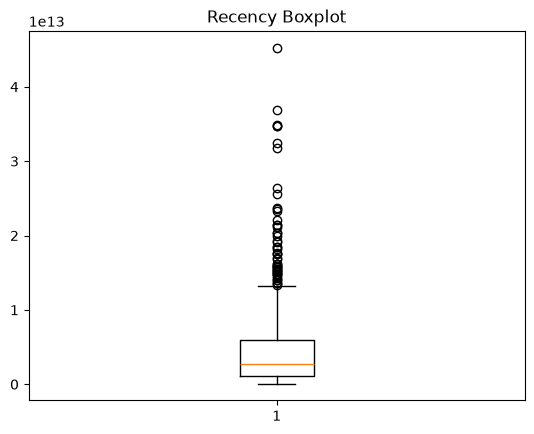

In [174]:
# Understanding the outier values
q1, q3= df_rfm.Recency.quantile([0.25,0.75])
iqr = q3-q1
low_fence = q1-1.5*iqr
high_fence = q1+1.5*iqr
print(low_fence, high_fence)

plt.boxplot(df_rfm['Recency'])
plt.title('Recency Boxplot')
plt.show()

In [175]:
# Understanding recency with quantile
df_rfm.Recency.quantile([0.20, 0.40, 0.60, 0.80, 0.99]).reset_index()

,index,Recency
0,0.20,11 days 00:00:00
1,0.40,24 days 00:00:00
2,0.60,42 days 09:35:59.999999
3,0.80,77 days 00:00:00
4,0.99,272 days 00:28:48


In [176]:
# Only 10 people bought more than 272 days ago which is only 1%
(df_rfm.Recency > pd.Timedelta(days=272)).sum()

np.int64(10)

In [177]:
# about 189 customer exits between 80th and 99th quantile
((df_rfm.Recency <= pd.Timedelta(days=272))&(df_rfm.Recency > pd.Timedelta(days=77))).sum()

# which means that about 80% of customers are buying and repeating whitin 77 days

np.int64(189)

## Conclusion

According to analysis above,

Point 1
- | Percentile Customers| Bought within    |
  | ----------          | ---------------- |
  | 20                  |    11 Days       |
  | 40                  |    24 Days       |
  | 60                  |    42 Days       |
  | 80                  |    77 Days       |
  | 99                  |   272 Days       |

Point 2

- Boxplot confirms there are a lot of outliers

Point 3

- According to the **IQR method**, highest of the customers have **bought within 97 days** that is roughly 100.

Conclusion

- 99% people buying within roughly 100 days, should be used for scoring with 5,4,3,2 scores and above 100 with 1 score

- As most purchases made within 100 days, scoring 5-4 dividing equally based on number of days and scoring 1 with purchase more than 100 days.

- According to Recency analysis with quantiles, following is the scoring method followed to score Recency

| Last Purchase in/ago   | Score  |
| --------------  | ------ |
|     25 Days     |  5     |
| 25-50 Days     |  4     |
| 50-75 Days     |  3     |
| 75-100 Days     |  2     |
| 100+ Days     |  1     |

In [178]:

conditions = [
    df_rfm['Recency'] < pd.Timedelta(days=25),
    (df_rfm['Recency'] < pd.Timedelta(days=50))&(df_rfm['Recency'] >= pd.Timedelta(days=25)),
    (df_rfm['Recency'] < pd.Timedelta(days=75))&(df_rfm['Recency'] >= pd.Timedelta(days=50)),
    (df_rfm['Recency'] < pd.Timedelta(days=100))&(df_rfm['Recency'] >= pd.Timedelta(days=75)),
    df_rfm['Recency'] >= pd.Timedelta(days=100)
]
scores = [1,2,3,4,5]

df_rfm['R_Score'] = np.select(conditions, scores)
df_rfm

,CustomerID,Recency,Frequency,Monetry,R_Score
0,CUST10000,13 days,23,21265.49,1
1,CUST10001,35 days,30,28654.31,2
2,CUST10002,18 days,24,23884.03,1
3,CUST10003,81 days,25,24206.03,4
4,CUST10004,8 days,19,25565.30,1
...,...,...,...,...,...
995,CUST10995,402 days,21,24325.19,5
996,CUST10996,15 days,21,21809.11,1
997,CUST10997,32 days,20,21120.48,2
998,CUST10998,126 days,25,29494.56,5


## B.
### Frequency Scoring Methodology


In [179]:
# Understanding how data is spread
df_rfm.Frequency.describe()

count    1000.000000
mean       23.050000
std         4.810472
min         6.000000
25%        20.000000
50%        23.000000
75%        26.000000
max        38.000000
Name: Frequency, dtype: float64

11.0 29.0


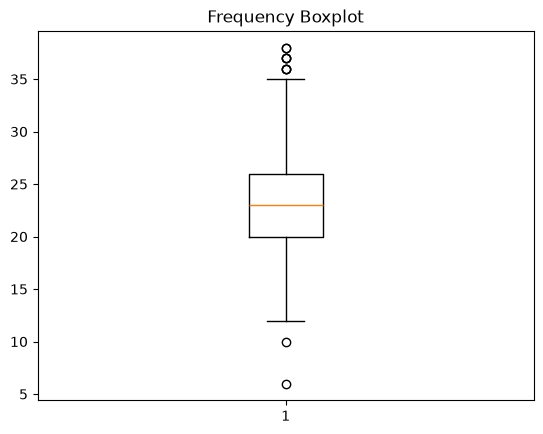

In [180]:
# Understanding outliers 
q1, q3 = df_rfm['Frequency'].quantile([0.25,0.75])
iqr = q3 -q1
low_fence = q1 - 1.5*iqr
high_fence = q1 + 1.5*iqr
print(low_fence, high_fence)

plt.boxplot(df_rfm['Frequency'])
plt.title('Frequency Boxplot')
plt.show()

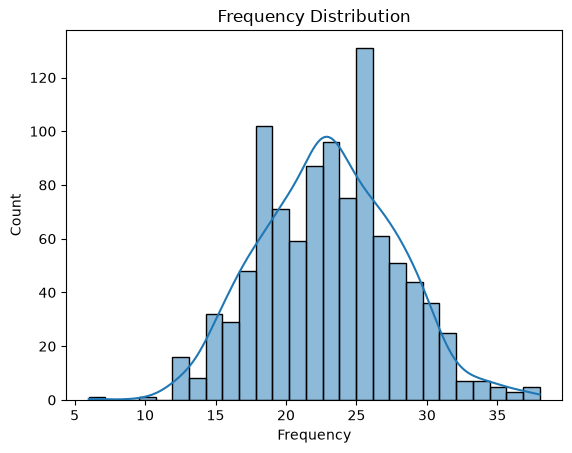

In [181]:
# Understanding the dustribution
sns.histplot(data=df_rfm, x='Frequency', kde=True)
plt.title('Frequency Distribution')
plt.show()

In [182]:
# Calculation transactions by customers per year
years_joined = ref_date.year - cust_df['JoinDate'].dt.year
df_rfm['Frequency_Per_Year'] = df_rfm['Frequency'] / years_joined

count    1000.000000
mean        9.996883
std         6.293209
min         2.400000
25%         5.750000
50%         7.750000
75%        11.625000
max        38.000000
Name: Frequency_Per_Year, dtype: float64


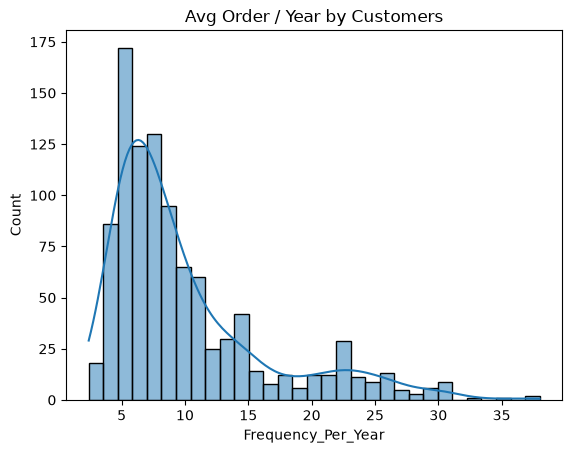

In [183]:
print(df_rfm['Frequency_Per_Year'].describe())

sns.histplot(data=df_rfm, x='Frequency_Per_Year', kde=True)
plt.title('Avg Order / Year by Customers')
plt.show()

## Conclusion

From above analysis, 

- Point 1

The **mean and median frequency is about 23** with a standard deviation of roughly 4. And **25 percentile is 20 and 75% percentile is 26** which suggests that average customers buys with a frequency of about 23 going up and down by 5 purchases normally.

- Point 2

The **low fence and high fence** from IQR also which is **11 and 29** also suggests that mostly customers bought with a frequency of 11 to 29.

- Point 3

The **boxplot and Histogram** also confirms the same points suggesting that most customers have a buying frequency of 10 to 30 and anyone having frequency out of the this Interval is an exceptional case.

- **Point 4**

But the point 4 presents a whole different story. The average order for each customer since the date they joined is very right skewed data with heavy right tails.

So this suggests that generally customers buy about 5-8 times normaly in a year.
But there are customers who buy exceptionally frequently.

1. Customer buying less than 5 times a year :   Very Infrequent   **(approx. one order a month)**
2. Customer buying between 6-9 times a year :   Low Frequency     **(approx. one order in 50 days)**
3. Customer buying between 10-14 times a year :   Average Buyer   **(approx. an order a month)**
4. Customer buying between 15-19 times a year :   High Frequency  **(approx. an order a month and 2 order next month)**

5. Customer buying 20+ times a year :   very Frequency  **(approx. 2 or 2+ order a month and 2 order next month)**

***

From all the points above, so dividing the frequency simply into 5 equal parts and then scoring it can be mis-leading and instead of this we raise the bar and emplying a new scoring methodology as shown below:

| Score | Frequency | Customer Type |
| ----- | --------- | ------------- |
| 1     |  <= 5     |very Infrequent|
| 2     |  6-9      | Low Frequency |
| 3     |  10-14    | Avg Buyer     |
| 4     |  15-19    |High Frequency |
| 5     |  20+      |Very Frequency |


In [184]:
# Scoring the F_Score

conditions = [
    df_rfm['Frequency_Per_Year'] <= 5,
    (df_rfm['Frequency_Per_Year'] <= 9)&(df_rfm['Frequency_Per_Year'] > 5),
    (df_rfm['Frequency_Per_Year'] <= 14)&(df_rfm['Frequency_Per_Year'] > 9),
    (df_rfm['Frequency_Per_Year'] <= 19)&(df_rfm['Frequency_Per_Year'] > 14),
    df_rfm['Frequency_Per_Year'] > 19,
]
f_score = [1,2,3,4,5]

df_rfm['F_Score'] = np.select(conditions, f_score)

In [185]:
# View
df_rfm.head()

,CustomerID,Recency,Frequency,Monetry,R_Score,Frequency_Per_Year,F_Score
0,CUST10000,13 days,23,21265.49,1,5.750000,2
1,CUST10001,35 days,30,28654.31,2,15.000000,4
2,CUST10002,18 days,24,23884.03,1,12.000000,3
3,CUST10003,81 days,25,24206.03,4,8.333333,2
4,CUST10004,8 days,19,25565.30,1,6.333333,2


## C.
### Monetry Scoring Methodology

In [186]:
# Understanding the spread of Monetry data
df_rfm['Monetry'].describe()

count     1000.00000
mean     23053.19966
std       5622.44101
min       5052.69000
25%      18965.46250
50%      22969.82000
75%      26827.39250
max      44784.99000
Name: Monetry, dtype: float64

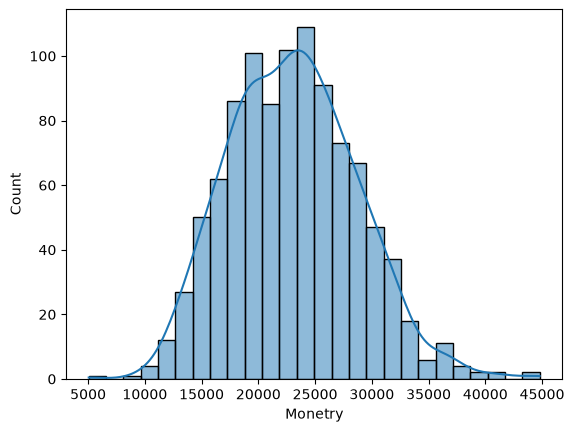

In [187]:
sns.histplot(data=df_rfm, x='Monetry', kde=True)
plt.show()

In [188]:
# Calculating Monetry per order per year
orders = trans_df.CustomerID.value_counts().sort_index().values
df_rfm['Monetry_Per_Order_Per_Year'] = df_rfm['Monetry']/orders/years_joined
df_rfm.sample(2)

,CustomerID,Recency,Frequency,Monetry,R_Score,Frequency_Per_Year,F_Score,Monetry_Per_Order_Per_Year
404,CUST10404,18 days,35,31433.00,1,17.5,4,449.042857
452,CUST10452,41 days,23,29971.16,2,4.6,1,260.618783


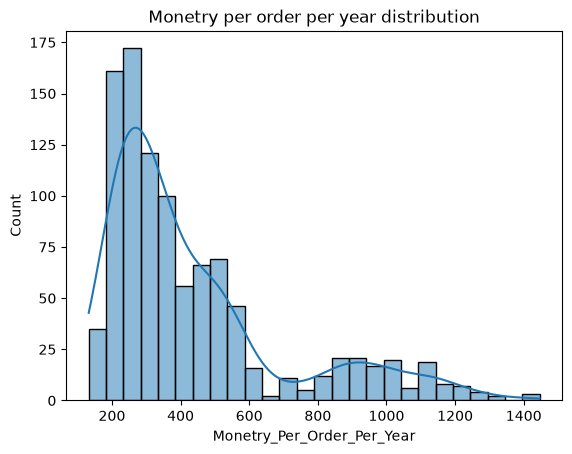

In [189]:
sns.histplot(data=df_rfm, x='Monetry_Per_Order_Per_Year', kde=True)
plt.title('Monetry per order per year distribution')
plt.show()

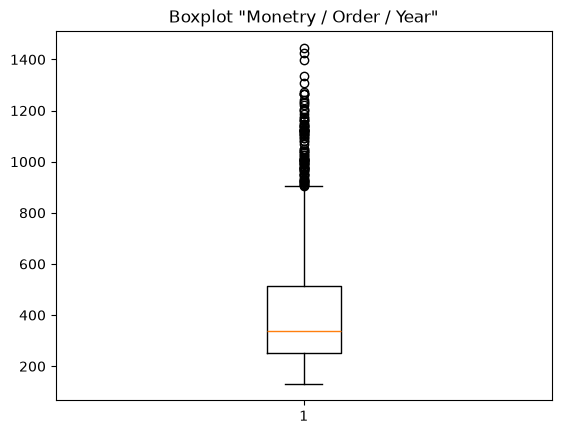

In [190]:
plt.boxplot(df_rfm['Monetry_Per_Order_Per_Year'])
plt.title('Boxplot "Monetry / Order / Year"')
plt.show()

## Conclusion

Based on the investigation above,
the scoring methodology is as follows:

| Score | Monetry/Order/Year | 
|-------|--------------------|
| 1     |  <= 200            |
| 2     |  201-400          |
| 3     |  401-600          |
| 4     |  601-800          |
| 5     |  800 +            |

In [191]:
# M_Scoring

conditions = [
    df_rfm['Monetry_Per_Order_Per_Year'] <= 200,
    (df_rfm['Monetry_Per_Order_Per_Year']<= 400)&(df_rfm['Monetry_Per_Order_Per_Year'] > 200),
    (df_rfm['Monetry_Per_Order_Per_Year']<= 600)&(df_rfm['Monetry_Per_Order_Per_Year'] > 400),
    (df_rfm['Monetry_Per_Order_Per_Year']<= 800)&(df_rfm['Monetry_Per_Order_Per_Year'] > 600),
    df_rfm['Monetry_Per_Order_Per_Year'] > 800,
]
m_score = [1,2,3,4,5]
df_rfm['M_Score'] = np.select(conditions, m_score)

In [192]:
# view
df_rfm.sample(5)

,CustomerID,Recency,Frequency,Monetry,R_Score,Frequency_Per_Year,F_Score,Monetry_Per_Order_Per_Year,M_Score
188,CUST10188,1 days,24,22906.42,1,12.00,3,477.217083,3
890,CUST10890,75 days,22,26338.17,4,5.50,2,299.297386,2
646,CUST10646,375 days,25,21739.28,5,6.25,2,217.392800,2
507,CUST10507,68 days,22,24291.75,3,11.00,3,552.085227,3
821,CUST10821,89 days,15,14003.31,4,5.00,1,311.184667,2


# Step 4: Combine Scores

In [193]:
# converting score dtype to str for concatenation
df_rfm[['R_Score','F_Score','M_Score']]=df_rfm[['R_Score','F_Score','M_Score']].astype(str)

# Combining the r f m  score
df_rfm['RFM_Score'] = df_rfm['R_Score']+df_rfm['F_Score']+df_rfm['M_Score']

df_rfm.sample(5)

,CustomerID,Recency,Frequency,Monetry,R_Score,Frequency_Per_Year,F_Score,Monetry_Per_Order_Per_Year,M_Score,RFM_Score
683,CUST10683,22 days,23,29468.39,1,11.50,3,640.617174,4,134
106,CUST10106,132 days,23,28357.19,5,11.50,3,616.460652,4,534
234,CUST10234,20 days,29,25985.53,1,5.80,2,179.210552,1,121
955,CUST10955,7 days,27,28094.19,1,9.00,2,346.841852,2,122
55,CUST10055,5 days,27,26342.37,1,6.75,2,243.910833,2,122


# Step 5: Assign Segments

In [194]:
# converting score dtype nack to int for assigning the segment
df_rfm[['R_Score','F_Score','M_Score']]=df_rfm[['R_Score','F_Score','M_Score']].astype(int)

### Segment Definition


In [195]:
conditions = [
    (df_rfm['R_Score'] >= 4) & (df_rfm['F_Score'] >= 4) & (df_rfm['M_Score'] >= 4),  # Champions
    (df_rfm['R_Score'] >= 3) & (df_rfm['F_Score'] >= 4) & (df_rfm['M_Score'] < 4),   # Loyal Customers
    (df_rfm['R_Score'] >= 4) & (df_rfm['F_Score'].between(2, 3)),                    # Potential Loyalist
    (df_rfm['R_Score'] <= 2) & (df_rfm['F_Score'] >= 3),                             # At Risk
    (df_rfm['R_Score'] <= 2) & (df_rfm['F_Score'] <= 2),                             # Lost
    (df_rfm['M_Score'] >= 4) & (df_rfm['F_Score'] < 3)                               # Big Spenders
]

segments = ['Champions', 'Loyal Customers', 'Potential Loyalist', 'At Risk', 'Lost', 'Big Spenders']
df_rfm['Customer_Segment'] = np.select(conditions, segments, default='Others')

In [196]:
seg_pop = df_rfm.Customer_Segment.value_counts().reset_index()
seg_pop
df_rfm

,CustomerID,Recency,Frequency,Monetry,R_Score,Frequency_Per_Year,F_Score,Monetry_Per_Order_Per_Year,M_Score,RFM_Score,Customer_Segment
0,CUST10000,13 days,23,21265.49,1,5.750000,2,231.146630,2,122,Lost
1,CUST10001,35 days,30,28654.31,2,15.000000,4,477.571833,3,243,At Risk
2,CUST10002,18 days,24,23884.03,1,12.000000,3,497.583958,3,133,At Risk
3,CUST10003,81 days,25,24206.03,4,8.333333,2,322.747067,2,422,Potential Loyalist
4,CUST10004,8 days,19,25565.30,1,6.333333,2,448.514035,3,123,Lost
...,...,...,...,...,...,...,...,...,...,...,...
995,CUST10995,402 days,21,24325.19,5,4.200000,1,231.668476,2,512,Others
996,CUST10996,15 days,21,21809.11,1,7.000000,2,346.176349,2,122,Lost
997,CUST10997,32 days,20,21120.48,2,10.000000,3,528.012000,3,233,At Risk
998,CUST10998,126 days,25,29494.56,5,8.333333,2,393.260800,2,522,Potential Loyalist


# Visualisations

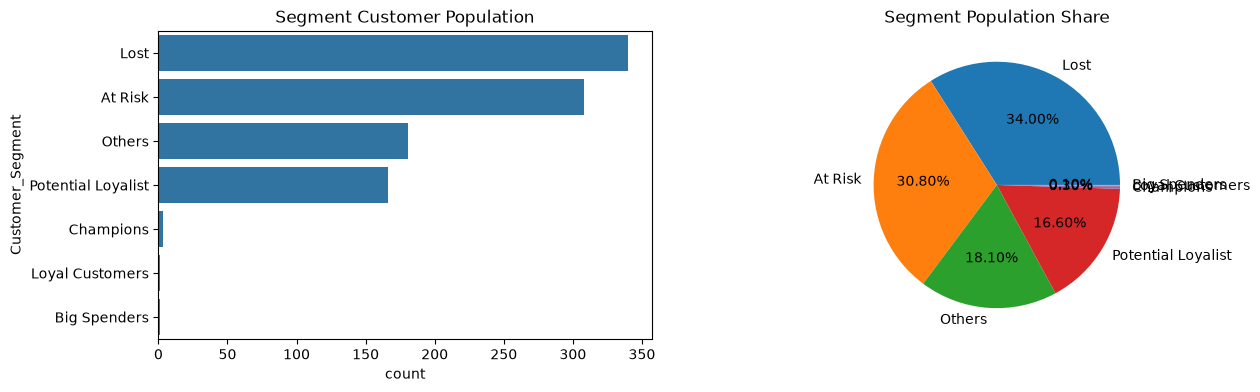

In [197]:
# Count of customers in each segment
fig, ax = plt.subplots(1,2, figsize=(14,4))

sns.barplot(data=seg_pop, y='Customer_Segment', x='count', ax=ax[0])
ax[0].set_title('Segment Customer Population')


ax[1].pie(seg_pop['count'], labels=seg_pop['Customer_Segment'], autopct='%1.2f%%')
ax[1].set_title('Segment Population Share')

plt.show()

In [198]:
# Revenue contribution per segment
seg_rev = df_rfm.groupby('Customer_Segment')['Monetry'].sum().reset_index()
seg_rev

,Customer_Segment,Monetry
0,At Risk,7576620.92
1,Big Spenders,22525.16
2,Champions,80675.86
3,Lost,7537655.30
4,Loyal Customers,28466.57
5,Others,3915657.46
6,Potential Loyalist,3891598.39


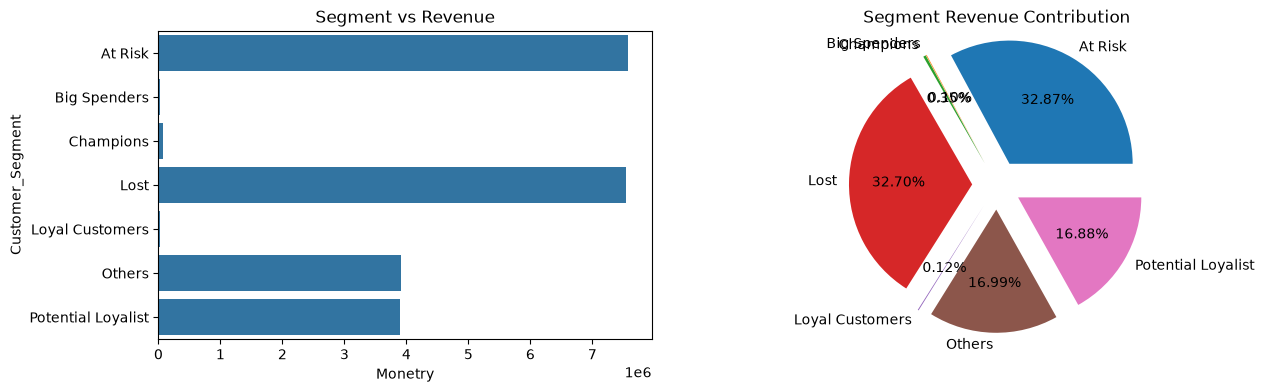

In [199]:
# Count of customers in each segment
fig, ax = plt.subplots(1,2, figsize=(14,4))

sns.barplot(data=seg_rev, y='Customer_Segment', x='Monetry', ax=ax[0])
ax[0].set_title('Segment vs Revenue')


ax[1].pie(seg_rev['Monetry'], labels=seg_rev['Customer_Segment'], autopct='%1.2f%%', explode=[0.2,0.2,0.2,0.2,0.2,0.2,0.2])
ax[1].set_title('Segment Revenue Contribution')

plt.show()

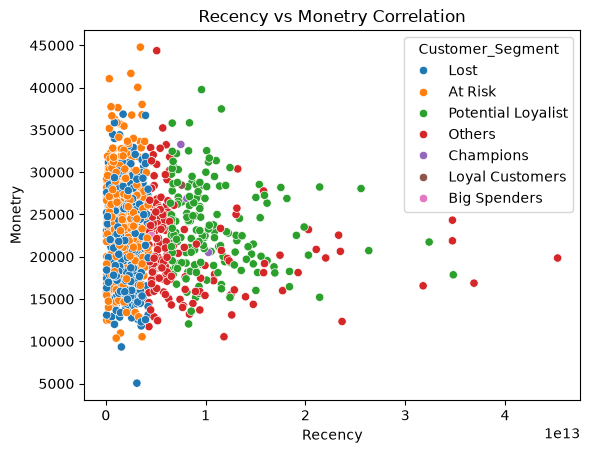

In [200]:
# Recency vs Monetary scatter plot colored by segment

sns.scatterplot(data=df_rfm, x='Recency', y='Monetry', hue='Customer_Segment')
plt.title('Recency vs Monetry Correlation')
plt.show()